# Phase 10 — Context-Cube Spectral Dynamics — revisited

**Goal:** extend Phase 8 from Möbius interaction coefficients to an exact spectral description of the \(2^n\) context-subset cube, **while explicitly detecting degenerate/flat signals**.

For \(n=4\) evidence cards, Phase 8 defines

\[
F:\{0,1\}^4\rightarrow\mathbb R,
\]

where \(F(S)\) is the measured quality (e.g. correctness / success probability) for context subset \(S\).

The central safeguard added in this revision is:

\[
\boxed{\operatorname{Var}_S F(S)\approx 0
\;\Longrightarrow\;
\text{higher-order spectral conclusions are not informative}}
\]

A flat signal is not a spectral failure: it should have
- zero one-bit sensitivity,
- zero Laplacian energy,
- Walsh energy only at order 0,
- no heat-flow evolution.

This notebook therefore separates **validation of the mathematics** from **interpretation of the experimental signal**.


## Why this follows Phase 8 naturally

Phase 8 already computes the Möbius expansion

\[
F(S)=\sum_{T\subseteq S}m(T).
\]

Möbius coefficients are excellent for causal interaction interpretation.

Walsh coefficients instead expand \(F\) in an **orthogonal basis**:

\[
\hat F(A)
=
2^{-n}
\sum_{x\in\{0,1\}^n}
F(x)(-1)^{A\cdot x}.
\]

Orthogonality gives Parseval energy and clean notions of spectral concentration, filtering and graph dynamics.

So:

- **Möbius:** "which subsets cooperate?"
- **Walsh:** "at which Boolean frequencies / orders does the response surface live?"

In [13]:
import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_EVIDENCE = 4
N_STATES = 1 << N_EVIDENCE

RESULT_CANDIDATES = [
    "phase8_qwen06_raw_results.csv",
    "phase8_frontier_raw_results.csv",
]

RESULT_PATH = None
for p in RESULT_CANDIDATES:
    if os.path.exists(p):
        RESULT_PATH = p
        break

if RESULT_PATH is None:
    raise FileNotFoundError(
        "Run Phase 8 first or place one of the expected raw result CSV files "
        "in the working directory."
    )

results = pd.read_csv(RESULT_PATH)
print("using:", RESULT_PATH)
print("rows:", len(results))

using: phase8_qwen06_raw_results.csv
rows: 192


## 0. Data-integrity and signal diagnostics

Before applying Walsh/Laplacian analysis, we verify for every `(provider, task_id)`:

1. all \(2^n\) masks are present;
2. masks are unique after aggregation;
3. the signal actually varies across subsets;
4. the number of repeated observations per mask is visible.

This prevents a mathematically correct spectral pipeline from being interpreted as an experimental discovery when the input signal is constant.


In [14]:
REQUIRED_COLUMNS = {"provider", "task_id", "family", "mask", "correct", "error"}
missing = REQUIRED_COLUMNS - set(results.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

results["mask"] = results["mask"].astype(int)

bad_masks = results.loc[
    (results["mask"] < 0) | (results["mask"] >= N_STATES),
    "mask"
]
if len(bad_masks):
    raise ValueError(f"Found masks outside [0,{N_STATES-1}]: {sorted(bad_masks.unique())}")

print("available columns:")
print(list(results.columns))
print("expected states per task:", N_STATES)


available columns:
['provider', 'requested_model', 'returned_model', 'task_id', 'family', 'mask', 'order', 'repeat', 'effort', 'correct_answer', 'parsed_answer', 'correct', 'raw_text', 'input_tokens', 'output_tokens', 'latency_sec', 'provider_cost_usd', 'error']
expected states per task: 16


In [15]:
def mask_order(mask):
    return int(mask).bit_count()

def count_unique_rounded(x, decimals=12):
    arr = x.to_numpy(dtype=float)
    return int(len(np.unique(np.round(arr, decimals))))

def population_std(x):
    return float(np.std(x.to_numpy(dtype=float), ddof=0))

valid = results[
    results["error"].isna()
    & results["correct"].notna()
].copy()

F_df = (
    valid
    .groupby(["provider", "task_id", "family", "mask"])
    .agg(
        F=("correct", "mean"),
        n=("correct", "size"),
    )
    .reset_index()
)

task_signal_diagnostics = (
    F_df
    .groupby(["provider", "task_id", "family"])
    .agg(
        n_masks=("mask", "nunique"),
        min_F=("F", "min"),
        max_F=("F", "max"),
        std_F=("F", population_std),
        n_unique_F=("F", count_unique_rounded),
        min_repeats_per_mask=("n", "min"),
        max_repeats_per_mask=("n", "max"),
    )
    .reset_index()
)

task_signal_diagnostics["range_F"] = (
    task_signal_diagnostics["max_F"] - task_signal_diagnostics["min_F"]
)
task_signal_diagnostics["complete_cube"] = (
    task_signal_diagnostics["n_masks"] == N_STATES
)
task_signal_diagnostics["flat_signal"] = (
    task_signal_diagnostics["std_F"] < 1e-12
)

display(F_df.head())
display(task_signal_diagnostics)

n_complete = int(task_signal_diagnostics["complete_cube"].sum())
n_flat = int(task_signal_diagnostics["flat_signal"].sum())

print(f"complete cubes: {n_complete}/{len(task_signal_diagnostics)}")
print(f"flat signals:   {n_flat}/{len(task_signal_diagnostics)}")

if n_flat:
    print(
        "\nWARNING: some task signals are constant across subsets. "
        "For those tasks, zero sensitivity / zero Laplacian energy / "
        "order-0-only Walsh energy are the mathematically correct result."
    )

task_signal_diagnostics.to_csv(
    "phase10_signal_diagnostics.csv",
    index=False,
)


,provider,task_id,family,mask,F,n
0,local,0,direct,0,1.0,1
1,local,0,direct,1,1.0,1
2,local,0,direct,2,1.0,1
3,local,0,direct,3,1.0,1
4,local,0,direct,4,1.0,1


,provider,task_id,family,n_masks,min_F,max_F,std_F,n_unique_F,min_repeats_per_mask,max_repeats_per_mask,range_F,complete_cube,flat_signal
0,local,0,direct,16,1.0,1.0,0.0,1,1,1,0.0,True,True
1,local,1,redundant,16,0.0,0.0,0.0,1,1,1,0.0,True,True
2,local,2,pair_chain,16,1.0,1.0,0.0,1,1,1,0.0,True,True
3,local,3,triple_chain,16,0.0,0.0,0.0,1,1,1,0.0,True,True
4,local,4,dual_path,16,1.0,1.0,0.0,1,1,1,0.0,True,True
5,local,5,direct,16,0.0,0.0,0.0,1,1,1,0.0,True,True
6,local,6,redundant,16,0.0,0.0,0.0,1,1,1,0.0,True,True
7,local,7,pair_chain,16,0.0,0.0,0.0,1,1,1,0.0,True,True
8,local,8,triple_chain,16,0.0,0.0,0.0,1,1,1,0.0,True,True
9,local,9,dual_path,16,0.0,0.0,0.0,1,1,1,0.0,True,True


complete cubes: 12/12
flat signals:   12/12



# A. Walsh–Hadamard transform

We use the convention

\[
\hat F(A)=2^{-n}\sum_x F(x)(-1)^{A\cdot x}.
\]

With this normalization,

\[
2^{-n}\sum_x F(x)^2
=
\sum_A \hat F(A)^2.
\]

That gives a clean energy decomposition by order \(|A|\).

In [16]:
def fwht(a):
    x = np.asarray(a, dtype=float).copy()
    n = len(x)
    h = 1
    while h < n:
        for i in range(0, n, h * 2):
            u = x[i:i+h].copy()
            v = x[i+h:i+2*h].copy()
            x[i:i+h] = u + v
            x[i+h:i+2*h] = u - v
        h *= 2
    return x

def walsh_coefficients(f):
    f = np.asarray(f, dtype=float)
    return fwht(f) / len(f)

def walsh_reconstruct(coeff):
    coeff = np.asarray(coeff, dtype=float)
    return fwht(coeff)

def walsh_energy_by_order(f, n_bits=N_EVIDENCE):
    coeff = walsh_coefficients(f)
    rows = []
    for order in range(n_bits + 1):
        ii = [m for m in range(1 << n_bits) if mask_order(m) == order]
        rows.append({
            "order": order,
            "energy": float(np.sum(coeff[ii] ** 2)),
            "n_coeffs": len(ii),
        })
    return pd.DataFrame(rows)

# ---------- Mandatory synthetic validation ----------
# 1) constant -> order 0 only
f_const = np.full(N_STATES, 0.5)

# 2) additive Boolean function -> orders 0 and 1 only
weights = np.array([1.0, 0.7, -0.4, 0.2])
def bits(mask):
    return np.array([(mask >> i) & 1 for i in range(N_EVIDENCE)], dtype=float)
f_add = np.array([0.3 + bits(m) @ weights for m in range(N_STATES)])

# 3) pure pair parity on bits 0,1 -> order 2
f_pair = np.array([
    (-1.0) ** ((((m >> 0) & 1) ^ ((m >> 1) & 1)))
    for m in range(N_STATES)
])

print("Synthetic Walsh checks")
for name, f_test in [
    ("constant", f_const),
    ("additive", f_add),
    ("pair_parity", f_pair),
]:
    e = walsh_energy_by_order(f_test)
    print("\n", name)
    display(e)

pair_energy = walsh_energy_by_order(f_pair).set_index("order")["energy"]
assert pair_energy.loc[2] > 1e-10, "Pair-parity test failed: no order-2 energy."
assert pair_energy.drop(index=2).abs().max() < 1e-10, (
    "Pair-parity test failed: energy leaked outside order 2."
)

# ---------- Real data ----------
walsh_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    coeff = walsh_coefficients(f)
    recon = walsh_reconstruct(coeff)
    err = float(np.max(np.abs(f - recon)))
    family = d["family"].iloc[0]

    for mask, coef in enumerate(coeff):
        walsh_rows.append({
            "provider": provider,
            "task_id": task_id,
            "family": family,
            "frequency_mask": mask,
            "order": mask_order(mask),
            "walsh": float(coef),
            "energy": float(coef * coef),
            "reconstruction_error": err,
        })

walsh_df = pd.DataFrame(walsh_rows)
print("max reconstruction error:", walsh_df["reconstruction_error"].max())
walsh_df.to_csv("phase10_walsh_coefficients.csv", index=False)


Synthetic Walsh checks

 constant


,order,energy,n_coeffs
0,0,0.25,1
1,1,0.00,4
2,2,0.00,6
3,3,0.00,4
4,4,0.00,1



 additive


,order,energy,n_coeffs
0,0,1.102500e+00,1
1,1,4.225000e-01,4
2,2,4.477787e-33,6
3,3,6.740755e-34,4
4,4,4.814825e-35,1



 pair_parity


,order,energy,n_coeffs
0,0,0.0,1
1,1,0.0,4
2,2,1.0,6
3,3,0.0,4
4,4,0.0,1


max reconstruction error: 0.0


,provider,order,mean_energy,std_energy,mean_energy_fraction,std_energy_fraction,n_tasks
0,local,0,0.25,0.452267,0.25,0.452267,12
1,local,1,0.00,0.000000,0.00,0.000000,12
2,local,2,0.00,0.000000,0.00,0.000000,12
3,local,3,0.00,0.000000,0.00,0.000000,12
4,local,4,0.00,0.000000,0.00,0.000000,12


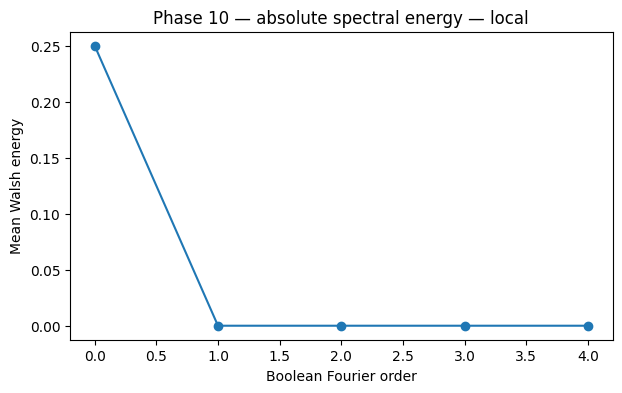

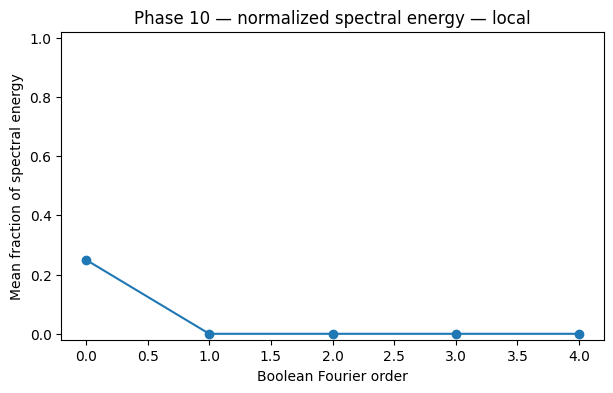

In [17]:
energy_order = (
    walsh_df
    .groupby(["provider","task_id","family","order"])
    .agg(
        energy=("energy","sum"),
        abs_mass=("walsh", lambda x: np.abs(x).sum()),
    )
    .reset_index()
)

energy_order["total_energy"] = (
    energy_order
    .groupby(["provider","task_id"])["energy"]
    .transform("sum")
)
energy_order["energy_fraction"] = np.where(
    energy_order["total_energy"] > 1e-15,
    energy_order["energy"] / energy_order["total_energy"],
    0.0,
)

energy_summary = (
    energy_order
    .groupby(["provider","order"])
    .agg(
        mean_energy=("energy","mean"),
        std_energy=("energy","std"),
        mean_energy_fraction=("energy_fraction","mean"),
        std_energy_fraction=("energy_fraction","std"),
        n_tasks=("task_id","nunique"),
    )
    .reset_index()
)

display(energy_summary)

for provider in sorted(energy_summary["provider"].unique()):
    d = energy_summary[energy_summary["provider"] == provider]

    plt.figure(figsize=(7,4))
    plt.plot(d["order"], d["mean_energy"], marker="o")
    plt.xlabel("Boolean Fourier order")
    plt.ylabel("Mean Walsh energy")
    plt.title(f"Phase 10 — absolute spectral energy — {provider}")
    plt.show()

    plt.figure(figsize=(7,4))
    plt.plot(d["order"], d["mean_energy_fraction"], marker="o")
    plt.xlabel("Boolean Fourier order")
    plt.ylabel("Mean fraction of spectral energy")
    plt.ylim(-0.02, 1.02)
    plt.title(f"Phase 10 — normalized spectral energy — {provider}")
    plt.show()

energy_order.to_csv("phase10_order_energy_per_task.csv", index=False)
energy_summary.to_csv("phase10_order_energy.csv", index=False)


# B. Stability to context perturbations

A one-card perturbation is a bit flip:

\[
x\rightarrow x\oplus e_i.
\]

Define the discrete derivative

\[
D_iF(x)=F(x\oplus e_i)-F(x).
\]

Then useful robustness metrics are:

\[
S_{\text{mean}}
=
\mathbb E_{x,i}|D_iF(x)|
\]

and

\[
S_{\max}
=
\max_{x,i}|D_iF(x)|.
\]

Smaller values mean the output surface is more stable to adding/removing a single evidence card.

In [18]:
robust_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    family = d["family"].iloc[0]

    diffs = []
    for x in range(N_STATES):
        for bit in range(N_EVIDENCE):
            y = x ^ (1 << bit)
            diffs.append(abs(f[y] - f[x]))

    robust_rows.append({
        "provider": provider,
        "task_id": task_id,
        "family": family,
        "mean_one_bit_sensitivity": float(np.mean(diffs)),
        "max_one_bit_sensitivity": float(np.max(diffs)),
        "rms_one_bit_sensitivity": float(np.sqrt(np.mean(np.square(diffs)))),
    })

robust_df = pd.DataFrame(robust_rows)
display(robust_df)

robust_summary = (
    robust_df
    .groupby(["provider","family"])
    .agg(
        mean_sensitivity=("mean_one_bit_sensitivity","mean"),
        max_sensitivity=("max_one_bit_sensitivity","mean"),
        n_tasks=("task_id","nunique"),
    )
    .reset_index()
)

display(robust_summary)
robust_df.to_csv("phase10_context_stability.csv", index=False)

,provider,task_id,family,mean_one_bit_sensitivity,max_one_bit_sensitivity,rms_one_bit_sensitivity
0,local,0,direct,0.0,0.0,0.0
1,local,1,redundant,0.0,0.0,0.0
2,local,2,pair_chain,0.0,0.0,0.0
3,local,3,triple_chain,0.0,0.0,0.0
4,local,4,dual_path,0.0,0.0,0.0
5,local,5,direct,0.0,0.0,0.0
6,local,6,redundant,0.0,0.0,0.0
7,local,7,pair_chain,0.0,0.0,0.0
8,local,8,triple_chain,0.0,0.0,0.0
9,local,9,dual_path,0.0,0.0,0.0


,provider,family,mean_sensitivity,max_sensitivity,n_tasks
0,local,direct,0.0,0.0,3
1,local,dual_path,0.0,0.0,2
2,local,pair_chain,0.0,0.0,2
3,local,redundant,0.0,0.0,3
4,local,triple_chain,0.0,0.0,2


# C. Hypercube graph Laplacian

The 16 context subsets form the vertices of a 4-dimensional hypercube.

Two vertices are adjacent if they differ by one evidence card.

Let

\[
L=D-A
\]

be the graph Laplacian.

The Walsh characters are exactly the eigenmodes of this graph.

This gives a precise bridge:

\[
\text{context subsets}
\leftrightarrow
\text{spatial graph}
\]

\[
\text{Walsh transform}
\leftrightarrow
\text{graph Fourier transform}.
\]

In [19]:
def hypercube_adjacency(n_bits):
    N = 1 << n_bits
    A = np.zeros((N, N), dtype=float)
    for x in range(N):
        for bit in range(n_bits):
            y = x ^ (1 << bit)
            A[x, y] = 1.0
    return A

A = hypercube_adjacency(N_EVIDENCE)
D = np.diag(A.sum(axis=1))
L = D - A

eigvals, eigvecs = np.linalg.eigh(L)

# The exact spectrum of Q_n is lambda_k = 2k with multiplicity C(n,k).
expected_eigs = []
for k in range(N_EVIDENCE + 1):
    expected_eigs.extend([2.0 * k] * math.comb(N_EVIDENCE, k))
expected_eigs = np.asarray(expected_eigs)

print("Laplacian eigenvalues:")
print(np.round(eigvals, 8))
print("expected eigenvalues:")
print(expected_eigs)
print("matches Q_n theory:", np.allclose(eigvals, expected_eigs, atol=1e-10))

assert np.allclose(eigvals, expected_eigs, atol=1e-10), (
    "Hypercube Laplacian spectrum does not match theory."
)


Laplacian eigenvalues:
[0. 2. 2. 2. 2. 4. 4. 4. 4. 4. 4. 6. 6. 6. 6. 8.]
expected eigenvalues:
[0. 2. 2. 2. 2. 4. 4. 4. 4. 4. 4. 6. 6. 6. 6. 8.]
matches Q_n theory: True


## Laplacian smoothness

A standard graph-stability measure is

\[
\mathcal E(F)=F^\top L F
=
\frac12\sum_{x\sim y}(F(x)-F(y))^2.
\]

Low energy means the response changes smoothly under one-card context perturbations.

High energy means strong context sensitivity.

In [20]:
def undirected_edge_differences(f):
    f = np.asarray(f, dtype=float)
    diffs = []
    for x in range(N_STATES):
        for bit in range(N_EVIDENCE):
            y = x ^ (1 << bit)
            if x < y:
                diffs.append(f[x] - f[y])
    return np.asarray(diffs)

lap_rows = []

for (provider, task_id), d in F_df.groupby(["provider","task_id"]):
    d = d.sort_values("mask")
    if len(d) != N_STATES:
        continue

    f = d["F"].to_numpy(dtype=float)
    family = d["family"].iloc[0]

    energy = float(f.T @ L @ f)
    norm = float(f.T @ f)
    edge_diff = undirected_edge_differences(f)
    edge_energy = float(np.sum(edge_diff ** 2))

    # For the combinatorial Laplacian: f^T L f = sum over undirected edges (fu-fv)^2.
    identity_error = abs(energy - edge_energy)

    lap_rows.append({
        "provider": provider,
        "task_id": task_id,
        "family": family,
        "signal_std": float(np.std(f, ddof=0)),
        "n_unique_signal": int(len(np.unique(np.round(f, 12)))),
        "flat_signal": bool(np.std(f, ddof=0) < 1e-12),
        "mean_abs_edge_difference": float(np.mean(np.abs(edge_diff))),
        "max_abs_edge_difference": float(np.max(np.abs(edge_diff))),
        "laplacian_energy": energy,
        "edge_energy": edge_energy,
        "laplacian_edge_identity_error": identity_error,
        "normalized_laplacian_energy": energy / max(norm, 1e-12),
    })

lap_df = pd.DataFrame(lap_rows)
display(lap_df)

print(
    "max |f^T L f - edge energy|:",
    lap_df["laplacian_edge_identity_error"].max()
)

lap_df.to_csv("phase10_laplacian_stability.csv", index=False)


,provider,task_id,family,signal_std,n_unique_signal,flat_signal,mean_abs_edge_difference,max_abs_edge_difference,laplacian_energy,edge_energy,laplacian_edge_identity_error,normalized_laplacian_energy
0,local,0,direct,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
1,local,1,redundant,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
2,local,2,pair_chain,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
3,local,3,triple_chain,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
4,local,4,dual_path,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
5,local,5,direct,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
6,local,6,redundant,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
7,local,7,pair_chain,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
8,local,8,triple_chain,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0
9,local,9,dual_path,0.0,1,True,0.0,0.0,0.0,0.0,0.0,0.0


max |f^T L f - edge energy|: 0.0


# C2. Optional: analyze utility separately from quality

The spectral object should be named explicitly.

If Phase 8 also saved a scalar utility

\[
U(S)=Q(S)-\lambda C_{\text{tokens}}(S)-\mu C_{\text{latency}}(S),
\]

do **not** mix it silently with `correct`.

A flat \(Q(S)\) with a non-flat \(U(S)\) means the combinatorial structure is coming from **cost penalties**, not answer quality.

If your raw CSV has a column literally named `utility`, the cell below builds an independent subset surface for it.


In [21]:
if "utility" in valid.columns:
    U_df = (
        valid
        .groupby(["provider", "task_id", "family", "mask"])
        .agg(
            U=("utility", "mean"),
            n=("utility", "size"),
        )
        .reset_index()
    )

    utility_diag = (
        U_df
        .groupby(["provider", "task_id", "family"])
        .agg(
            n_masks=("mask", "nunique"),
            min_U=("U", "min"),
            max_U=("U", "max"),
            std_U=("U", population_std),
            n_unique_U=("U", count_unique_rounded),
        )
        .reset_index()
    )

    utility_diag["range_U"] = (
        utility_diag["max_U"] - utility_diag["min_U"]
    )
    utility_diag["flat_utility"] = (
        utility_diag["std_U"] < 1e-12
    )

    display(utility_diag)
else:
    print(
        "No column named 'utility' in the raw results. "
        "If Phase 8 computes utility under another name, "
        "add that column explicitly here."
    )


No column named 'utility' in the raw results. If Phase 8 computes utility under another name, add that column explicitly here.


# D. Diffusion and time constants on the context cube

A mathematically clean analogue of a stable dissipative dynamics is the graph heat equation:

\[
\frac{\partial \psi}{\partial t}
=
-\kappa L\psi.
\]

Solution:

\[
\psi(t)=e^{-\kappa Lt}\psi(0).
\]

For a Laplacian eigenmode with eigenvalue \(\lambda_k\),

\[
a_k(t)=a_k(0)e^{-\kappa\lambda_k t}.
\]

Therefore its time constant is

\[
\tau_k=\frac{1}{\kappa\lambda_k},
\qquad \lambda_k>0.
\]

On the \(n\)-cube, higher-order Walsh modes have larger Laplacian eigenvalues, hence decay faster under diffusion.

This gives a rigorous meaning to "fast" and "slow" context modes.

In [22]:
KAPPA = 1.0

unique_eigs = sorted(set(np.round(eigvals, 10)))

tau_rows = []
for lam in unique_eigs:
    tau = np.inf if abs(lam) < 1e-12 else 1.0 / (KAPPA * lam)
    tau_rows.append({
        "laplacian_eigenvalue": lam,
        "tau": tau,
    })

tau_df = pd.DataFrame(tau_rows)
display(tau_df)
tau_df.to_csv("phase10_diffusion_time_constants.csv", index=False)

,laplacian_eigenvalue,tau
0,0.0,inf
1,2.0,0.500000
2,4.0,0.250000
3,6.0,0.166667
4,8.0,0.125000


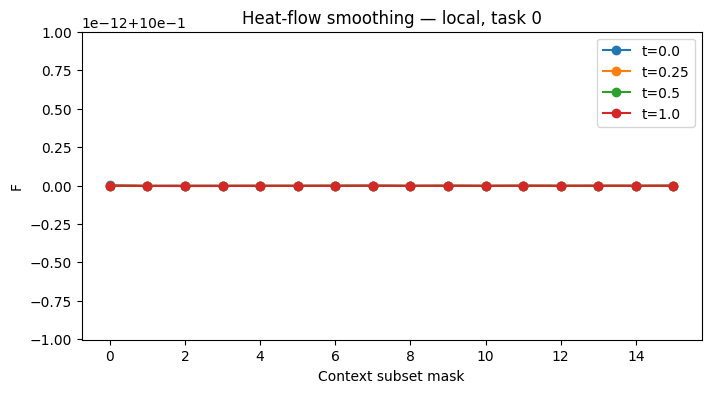

In [23]:
def heat_evolve(f, t, kappa=1.0):
    vals, vecs = np.linalg.eigh(L)
    coeff = vecs.T @ np.asarray(f, dtype=float)
    evolved = coeff * np.exp(-kappa * vals * t)
    return vecs @ evolved

example_group = next(iter(F_df.groupby(["provider","task_id"])), None)

if example_group is not None:
    (provider, task_id), d = example_group
    d = d.sort_values("mask")
    if len(d) == N_STATES:
        f0 = d["F"].to_numpy(dtype=float)

        plt.figure(figsize=(8,4))
        for t in [0.0, 0.25, 0.5, 1.0]:
            ft = heat_evolve(f0, t=t, kappa=KAPPA)
            plt.plot(range(N_STATES), ft, marker="o", label=f"t={t}")

        plt.xlabel("Context subset mask")
        plt.ylabel("F")
        plt.title(f"Heat-flow smoothing — {provider}, task {task_id}")
        plt.legend()
        plt.show()

# E. Schrödinger-style dynamics on the same graph

For comparison, replace dissipative heat flow with

\[
i\frac{\partial\psi}{\partial t}
=
L\psi.
\]

Then

\[
\psi(t)=e^{-iLt}\psi(0).
\]

Unlike diffusion, this evolution preserves the \(L_2\) norm:

\[
\|\psi(t)\|_2=\|\psi(0)\|_2.
\]

So:

- **heat equation:** useful analogue for forgetting, smoothing, stable relaxation;
- **Schrödinger equation:** useful analogue for phase-preserving propagation / interference;
- neither implies that the neural network is physically quantum.

For AI, the value is the mathematical inductive bias: spatial coupling, modes, phase, conservation versus dissipation.

,t,norm,norm_error,relative_probability_mass
0,0.00,4.0,-3.108624e-15,1.0
1,0.25,4.0,-3.108624e-15,1.0
2,0.50,4.0,-3.108624e-15,1.0
3,0.75,4.0,-2.664535e-15,1.0
4,1.00,4.0,-3.108624e-15,1.0
5,1.25,4.0,-2.664535e-15,1.0
6,1.50,4.0,-2.664535e-15,1.0
7,1.75,4.0,-2.664535e-15,1.0
8,2.00,4.0,-3.108624e-15,1.0
9,2.25,4.0,-2.664535e-15,1.0


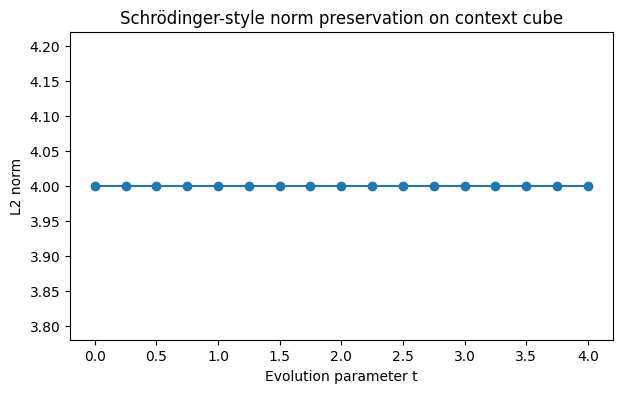

In [24]:
def schrodinger_evolve(psi0, t):
    vals, vecs = np.linalg.eigh(L)
    coeff = vecs.T @ np.asarray(psi0, dtype=complex)
    evolved = coeff * np.exp(-1j * vals * t)
    return vecs @ evolved

if example_group is not None:
    (provider, task_id), d = example_group
    d = d.sort_values("mask")
    if len(d) == N_STATES:
        psi0 = d["F"].to_numpy(dtype=float).astype(complex)

        rows = []
        norm0 = np.linalg.norm(psi0)
        mass0 = float(np.sum(np.abs(psi0) ** 2))

        for t in np.linspace(0, 4, 17):
            psi = schrodinger_evolve(psi0, t)
            mass = float(np.sum(np.abs(psi) ** 2))
            rows.append({
                "t": float(t),
                "norm": float(np.linalg.norm(psi)),
                "norm_error": float(np.linalg.norm(psi) - norm0),
                "relative_probability_mass": (
                    mass / mass0 if mass0 > 1e-15 else np.nan
                ),
            })

        sch_df = pd.DataFrame(rows)
        display(sch_df)

        plt.figure(figsize=(7,4))
        plt.plot(sch_df["t"], sch_df["norm"], marker="o")
        plt.xlabel("Evolution parameter t")
        plt.ylabel("L2 norm")
        plt.title("Schrödinger-style norm preservation on context cube")
        plt.show()


# F. How Phase 9 and Phase 10 fit together

### Phase 9
The "space" is mainly **token position**, while network depth acts as a time-like coordinate.

We measure perturbation propagation directly inside a Transformer.

### Phase 10
The "space" is the **graph of context subsets**.

We know the geometry exactly: a Boolean hypercube.

That makes graph Fourier, diffusion, time constants and Schrödinger-style propagation mathematically exact on the benchmark domain.

## Future bridge

A future model could have a state

\[
\psi(x,\ell)
\]

where \(x\) is token/context position and \(\ell\) is depth, with a learned operator

\[
\mathcal H_\theta
=
\mathcal H_{\text{local}}
+
\mathcal H_{\text{attention}}
+
\mathcal H_{\text{memory}}.
\]

Then the central experimental question becomes:

> do measured causal responses from Phase 7–10 support a compact dynamical law?

That is a much stronger question than merely asking whether Fourier or Schrödinger-inspired layers can be inserted into a Transformer.

# G. Interpretation gate before proceeding to a new model

Before using Phase 10 as evidence for a new dynamical architecture, require:

1. **Synthetic validation passes**
   - constant \(\to\) order 0 only;
   - additive \(\to\) order 0/1;
   - pair parity \(\to\) order 2.

2. **Real signals are non-degenerate**
   - enough tasks satisfy \(\operatorname{std}_S F(S)>0\);
   - there is more than one unique subset value.

3. **Quality and utility are separated**
   - if only utility varies, say so explicitly.

4. **Phase-9 trajectories show shape variability**
   - not only different final amplitudes.

Only after these checks should we test the proposed structured generative dynamics

\[
dz_t=
\left[-M_\theta(z,t)\nabla U_\theta(z,t)
+A_\theta(z,t)\nabla H_\theta(z,t)\right]dt
+G_\theta(z,t)dW_t,
\]

with

\[
M_\theta=M_\theta^\top\succeq 0,
\qquad
A_\theta^\top=-A_\theta.
\]

That experiment is deliberately postponed until the diagnostics are trustworthy.
